# Real-World Dataset Analysis Project: Telecom Customer Churn
**AI ML Research Specialist Internship — Task 3** · Submitted by: Pranav

## 1. Dataset Selection and Context
**Dataset:** *Telco Customer Churn*, a public sample dataset published by IBM (originally used in IBM Watson Analytics tutorials), widely used for churn-analysis practice. Source file: `https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv`.

**Why this dataset:** it describes a real business problem (customers leaving a subscription service), has a mix of numeric and categorical variables, and needs genuine cleaning work (a numeric column stored as text, redundant category labels).

**Business context:** a telecom company sells phone and internet services on monthly, one-year or two-year contracts. Acquiring a new customer usually costs more than keeping an existing one, so understanding *who churns and why* helps the company decide where to focus retention efforts.

**Data description (7,043 customers, 21 columns):** each row is one customer.
| Group | Columns |
|---|---|
| Demographics | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Account | `tenure` (months with company), `Contract`, `PaperlessBilling`, `PaymentMethod` |
| Services | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Charges | `MonthlyCharges`, `TotalCharges` |
| Target | `Churn` (Yes = left within the last month) |

**Analytical objectives**
1. How large is churn, and how much monthly revenue does it represent?
2. Which customer, account and service characteristics are associated with higher churn?
3. What practical recommendations follow?

**Caveat:** this is an anonymised sample dataset from a single snapshot. Findings show *associations*, not proven causes, and may not transfer to another company or period.

**Notebook structure:** 1 Context · 2 Setup & loading · 3 Exploration · 4 Cleaning & preprocessing · 5 Exploratory analysis · 6 Visualizations · 7 Findings, interpretation & recommendations

## 2. Setup and Data Loading

In [1]:
import os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
pd.set_option("display.max_columns", 30, "display.width", 130)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
COL = {"No": "#4C6EF5", "Yes": "#E8590C"}          # blue = retained, orange = churned (used in every chart)

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
LOCAL = "Telco-Customer-Churn.csv"
if os.path.exists(LOCAL):
    raw = pd.read_csv(LOCAL)
else:
    raw = pd.read_csv(URL); raw.to_csv(LOCAL, index=False)      # cache a local copy
print("Loaded:", raw.shape)
raw.head()

Loaded: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Exploring the Dataset

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
print("Duplicate rows         :", raw.duplicated().sum())
print("Duplicate customerID   :", raw["customerID"].duplicated().sum())
print("Missing values (NaN)   :", int(raw.isna().sum().sum()))
print("\nUnique values per categorical column:")
cats = raw.select_dtypes(exclude="number").columns.drop(["customerID", "TotalCharges"])
for c in cats: print(f"  {c:18}", sorted(raw[c].unique()))

Duplicate rows         : 0
Duplicate customerID   : 0
Missing values (NaN)   : 0

Unique values per categorical column:
  gender             ['Female', 'Male']
  Partner            ['No', 'Yes']
  Dependents         ['No', 'Yes']
  PhoneService       ['No', 'Yes']
  MultipleLines      ['No', 'No phone service', 'Yes']
  InternetService    ['DSL', 'Fiber optic', 'No']
  OnlineSecurity     ['No', 'No internet service', 'Yes']
  OnlineBackup       ['No', 'No internet service', 'Yes']
  DeviceProtection   ['No', 'No internet service', 'Yes']
  TechSupport        ['No', 'No internet service', 'Yes']
  StreamingTV        ['No', 'No internet service', 'Yes']
  StreamingMovies    ['No', 'No internet service', 'Yes']
  Contract           ['Month-to-month', 'One year', 'Two year']
  PaperlessBilling   ['No', 'Yes']
  PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
  Churn              ['No', 'Yes']


`info()` reports no missing values, but `TotalCharges` has type `str`, although it should be numeric. A numeric column stored as text usually means hidden bad values, so I check it next.

In [4]:
tc = pd.to_numeric(raw["TotalCharges"], errors="coerce")
bad = raw[tc.isna()]
print("Non-numeric TotalCharges values:", len(bad), "| distinct raw values:", bad["TotalCharges"].unique())
print("Their tenure values            :", bad["tenure"].unique(), "| their Churn:", bad["Churn"].unique())

Non-numeric TotalCharges values: 11 | distinct raw values: <StringArray>
[' ']
Length: 1, dtype: str
Their tenure values            : [0] | their Churn: <StringArray>
['No']
Length: 1, dtype: str


In [5]:
raw.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [6]:
print("Target balance:")
print(pd.DataFrame({"count": raw["Churn"].value_counts(), "share": raw["Churn"].value_counts(normalize=True).round(3)}))

Target balance:
       count  share
Churn              
No      5174  0.735
Yes     1869  0.265


**Observations:** The dataset has 7,043 unique customers, no duplicate rows or IDs and no NaN values, so on the surface it looks clean. However, `TotalCharges` is stored as text because 11 rows contain a single blank space. All 11 customers have tenure 0 and have not churned, so they are brand-new customers who have not yet been billed. The target is imbalanced: 26.5% of customers churned (1,869) against 73.5% retained (5,174). Several columns also contain labels such as 'No internet service' and 'No phone service' that repeat information found in other columns.

## 4. Data Cleaning and Preprocessing

All cleaning is done on a copy (`df`), so `raw` stays unchanged. Each step states the problem, the decision and the reason.

In [7]:
df = raw.copy()

# 1) Wrong data type: TotalCharges is text because 11 values are blank spaces.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
# Those 11 customers all have tenure = 0 (just signed up, not yet billed), so 0 is the true total, not a guess.
assert (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all()
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

# 2) Inconsistent encoding: SeniorCitizen is 0/1 while every other flag is Yes/No.
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# 3) Redundant labels: 'No internet service' / 'No phone service' repeat information already in
#    InternetService / PhoneService, so they are merged into 'No' for the add-on columns.
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df[addons] = df[addons].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

# 4) Target as 0/1 for calculations, and categorical dtypes for the text columns.
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)
for c in df.select_dtypes("object").columns.union(df.select_dtypes("string").columns).drop("customerID"):
    df[c] = df[c].astype("category")

# 5) Duplicates: none found in Section 3, re-checked after cleaning.
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Missing values after cleaning:", int(df.isna().sum().sum()))
print("TotalCharges dtype:", df["TotalCharges"].dtype)
print("Add-on labels now:", sorted(df["OnlineSecurity"].unique()), "| MultipleLines:", sorted(df["MultipleLines"].unique()))

Duplicate rows after cleaning: 0
Missing values after cleaning: 0
TotalCharges dtype: float64
Add-on labels now: ['No', 'Yes'] | MultipleLines: ['No', 'Yes']


### 4.1 Consistency checks and outliers

In [8]:
# TotalCharges should be roughly tenure x MonthlyCharges (prices change over time, so not exact).
est = df["tenure"] * df["MonthlyCharges"]
rel = ((df["TotalCharges"] - est) / est.where(est > 0)).dropna()
print("TotalCharges vs tenure*MonthlyCharges: median relative difference = {:.1%}, 90% of customers within ±{:.0%}".format(rel.median(), rel.abs().quantile(.9)))

print("\nOutlier check (IQR rule, 1.5 x IQR):")
for c in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df[c].quantile([.25, .75]); lo, hi = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
    n = ((df[c] < lo) | (df[c] > hi)).sum()
    print(f"  {c:15} range [{df[c].min():.1f}, {df[c].max():.1f}] | fences [{lo:.1f}, {hi:.1f}] | outliers: {n}")
print("\nSkewness:", df[["tenure", "MonthlyCharges", "TotalCharges"]].skew().round(2).to_dict())

TotalCharges vs tenure*MonthlyCharges: median relative difference = 0.0%, 90% of customers within ±8%

Outlier check (IQR rule, 1.5 x IQR):
  tenure          range [0.0, 72.0] | fences [-60.0, 124.0] | outliers: 0
  MonthlyCharges  range [18.2, 118.8] | fences [-46.0, 171.4] | outliers: 0
  TotalCharges    range [0.0, 8684.8] | fences [-4683.5, 8868.7] | outliers: 0

Skewness: {'tenure': 0.24, 'MonthlyCharges': -0.22, 'TotalCharges': 0.96}


### 4.2 Feature engineering

In [9]:
df["tenure_group"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
df["n_addons"] = (df[addons] == "Yes").sum(axis=1)                         # number of add-on services used
df["has_internet"] = (df["InternetService"] != "No").map({True: "Yes", False: "No"})
df["autopay"] = df["PaymentMethod"].str.contains("automatic").map({True: "Automatic", False: "Manual"})
df["charge_band"] = pd.qcut(df["MonthlyCharges"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
print(df[["tenure_group", "n_addons", "autopay", "charge_band"]].describe(include="all").T[["count", "unique", "top"]])
print("\nFinal analysis table:", df.shape)
df.to_csv("telco_churn_clean.csv", index=False)

               count unique      top
tenure_group    7043      4  49-72 m
n_addons      7043.0    NaN      NaN
autopay         7043      2   Manual
charge_band     7043      4       Q2

Final analysis table: (7043, 27)


**Observations:** After cleaning, there are still 7,043 rows (no customers were dropped), no missing values, and `TotalCharges` is numeric. The 11 blank values were set to 0 because those customers had a tenure of 0 months, so no charges had been billed. `TotalCharges` is consistent with `tenure × MonthlyCharges` (median difference 0%, 90% of customers within ±8%; the gap is expected as prices change). The IQR rule flags **no outliers** in `tenure`, `MonthlyCharges` or `TotalCharges`, so nothing was removed or capped. `TotalCharges` is mildly right-skewed (0.96), which is natural for a cumulative amount. I kept all values, because none are errors.

## 5. Exploratory Data Analysis

### 5.1 Overall churn and revenue impact

In [10]:
total = len(df); churned = df["churn_flag"].sum()
print(f"Customers: {total:,} | churned: {churned:,} ({churned/total:.1%})")
mrr = df["MonthlyCharges"].sum(); lost = df.loc[df["churn_flag"] == 1, "MonthlyCharges"].sum()
print(f"Monthly recurring revenue: {mrr:,.0f} | from churned customers: {lost:,.0f} ({lost/mrr:.1%})")
print("Average monthly charge  - churned: {:.2f} | retained: {:.2f}".format(
      df.loc[df.churn_flag==1,'MonthlyCharges'].mean(), df.loc[df.churn_flag==0,'MonthlyCharges'].mean()))
print("Median tenure (months)  - churned: {:.0f} | retained: {:.0f}".format(
      df.loc[df.churn_flag==1,'tenure'].median(), df.loc[df.churn_flag==0,'tenure'].median()))

Customers: 7,043 | churned: 1,869 (26.5%)
Monthly recurring revenue: 456,117 | from churned customers: 139,131 (30.5%)
Average monthly charge  - churned: 74.44 | retained: 61.27
Median tenure (months)  - churned: 10 | retained: 38


### 5.2 Churn rate by each categorical variable

In [11]:
cat_cols = ["gender","SeniorCitizen","Partner","Dependents","PhoneService","MultipleLines","InternetService","OnlineSecurity","OnlineBackup",
            "DeviceProtection","TechSupport","StreamingTV","StreamingMovies","Contract","PaperlessBilling","PaymentMethod","tenure_group"]
base = df["churn_flag"].mean()
rows = []
for c in cat_cols:
    for lvl, g in df.groupby(c, observed=True)["churn_flag"]:
        rows.append((c, lvl, len(g), g.mean()))
rates = pd.DataFrame(rows, columns=["variable", "level", "customers", "churn_rate"])
rates["vs_overall"] = (rates["churn_rate"] - base).round(3)
print("Overall churn rate:", round(base, 3), "\n\nHighest churn groups (min 300 customers):")
display(rates[rates.customers >= 300].sort_values("churn_rate", ascending=False).head(8).round(3).reset_index(drop=True))
print("Lowest churn groups:")
display(rates[rates.customers >= 300].sort_values("churn_rate").head(6).round(3).reset_index(drop=True))

Overall churn rate: 0.265 

Highest churn groups (min 300 customers):


,variable,level,customers,churn_rate,vs_overall
0,tenure_group,0-12 m,2186,0.474,0.209
1,PaymentMethod,Electronic check,2365,0.453,0.187
2,Contract,Month-to-month,3875,0.427,0.162
3,InternetService,Fiber optic,3096,0.419,0.154
4,SeniorCitizen,Yes,1142,0.417,0.151
5,PaperlessBilling,Yes,4171,0.336,0.070
6,Partner,No,3641,0.330,0.064
7,OnlineSecurity,No,5024,0.313,0.048


Lowest churn groups:


,variable,level,customers,churn_rate,vs_overall
0,Contract,Two year,1695,0.028,-0.237
1,InternetService,No,1526,0.074,-0.191
2,tenure_group,49-72 m,2239,0.095,-0.170
3,Contract,One year,1473,0.113,-0.153
4,OnlineSecurity,Yes,2019,0.146,-0.119
5,TechSupport,Yes,2044,0.152,-0.114


### 5.3 Statistical tests: which variables are most strongly associated with churn?

In [12]:
def cramers_v(x, y):
    t = pd.crosstab(x, y); chi2, p, dof, _ = stats.chi2_contingency(t)
    n = t.values.sum(); return np.sqrt(chi2 / (n * (min(t.shape) - 1))), p
res = pd.DataFrame([(c, *cramers_v(df[c], df["Churn"])) for c in cat_cols], columns=["variable", "cramers_v", "p_value"])
res["significant"] = res["p_value"] < 0.05
res = res.sort_values("cramers_v", ascending=False).reset_index(drop=True)
display(res.round(4).head(10))
print("Not significant at 5%:", res.loc[~res.significant, "variable"].tolist())

print("\nNumeric variables vs churn (Mann-Whitney U, robust to skew):")
for c in ["tenure", "MonthlyCharges", "TotalCharges"]:
    a, b = df.loc[df.churn_flag == 1, c], df.loc[df.churn_flag == 0, c]
    u, p = stats.mannwhitneyu(a, b); print(f"  {c:15} median churned {a.median():8.1f} | retained {b.median():8.1f} | p = {p:.2e}")

num = df[["tenure", "MonthlyCharges", "TotalCharges", "n_addons", "churn_flag"]]
print("\nCorrelation with churn_flag:"); print(num.corr()["churn_flag"].drop("churn_flag").round(3))

,variable,cramers_v,p_value,significant
0,Contract,0.4101,0.0,True
1,tenure_group,0.3486,0.0,True
2,InternetService,0.3225,0.0,True
3,PaymentMethod,0.3034,0.0,True
4,PaperlessBilling,0.1915,0.0,True
5,OnlineSecurity,0.1709,0.0,True
6,TechSupport,0.1643,0.0,True
7,Dependents,0.1639,0.0,True
8,SeniorCitizen,0.1505,0.0,True
9,Partner,0.1501,0.0,True


Not significant at 5%: ['PhoneService', 'gender']

Numeric variables vs churn (Mann-Whitney U, robust to skew):


  tenure          median churned     10.0 | retained     38.0 | p = 2.42e-208
  MonthlyCharges  median churned     79.7 | retained     64.4 | p = 3.31e-54
  TotalCharges    median churned    703.5 | retained   1679.5 | p = 5.69e-83

Correlation with churn_flag:
tenure           -0.352
MonthlyCharges    0.193
TotalCharges     -0.198
n_addons         -0.088
Name: churn_flag, dtype: float64


Cramér's V runs from 0 (no association) to 1 (perfect association); roughly, below 0.1 is negligible, 0.1–0.3 weak to moderate, above 0.3 strong.

### 5.4 Customer segments

In [13]:
df["risk_profile"] = np.where((df.Contract == "Month-to-month") & (df.InternetService == "Fiber optic") & (df.PaymentMethod == "Electronic check"),
                              "M2M + Fiber + E-check", "All other customers")
seg = df.groupby("risk_profile").agg(customers=("churn_flag", "size"), churn_rate=("churn_flag", "mean"),
                                     avg_monthly=("MonthlyCharges", "mean"), median_tenure=("tenure", "median")).round(3)
display(seg)
share = df.loc[df.risk_profile != "All other customers", "churn_flag"].sum() / df["churn_flag"].sum()
print(f"This one profile holds {seg.loc['M2M + Fiber + E-check','customers']/len(df):.1%} of customers but {share:.1%} of all churners.")

print("\nChurn rate by contract x tenure group:")
display(df.pivot_table(index="Contract", columns="tenure_group", values="churn_flag", aggfunc="mean", observed=True).round(3))

,customers,churn_rate,avg_monthly,median_tenure
risk_profile,,,,
All other customers,5736,0.188,59.653,34.0
M2M + Fiber + E-check,1307,0.604,87.183,13.0


This one profile holds 18.6% of customers but 42.2% of all churners.

Churn rate by contract x tenure group:


tenure_group,0-12 m,13-24 m,25-48 m,49-72 m
Contract,,,,
Month-to-month,0.514,0.377,0.329,0.260
One year,0.105,0.081,0.106,0.129
Two year,0.000,0.000,0.022,0.033


**Observations:**
- **Scale of churn:** 26.5% of customers churned, and they account for 30.5% of monthly recurring revenue (139,131 of 456,117), because churned customers pay more per month on average (74.44 vs 61.27).
- **Contract is the strongest factor** (Cramér's V = 0.41): churn is 42.7% on month-to-month contracts, 11.3% on one-year and 2.8% on two-year contracts.
- **Tenure matters:** median tenure is 10 months for churned and 38 months for retained customers; churn falls from 47.4% in the first year to 9.5% after four years (correlation with churn: -0.35).
- **Internet service and payment:** fiber optic customers churn at 41.9% (DSL 19.0%, no internet 7.4%), and electronic-check payers at 45.3% versus 15–19% for other payment methods; customers on automatic payment churn at 16.0% versus 34.7% on manual payment.
- **Support and security add-ons:** customers with online security or tech support churn at about 15% versus 31% without online security. Among internet users, churn drops from 52.2% with no add-ons to 5.3% with all six.
- **Weak or no link:** gender and phone service show no significant association with churn (p > 0.05).
- **High-risk profile:** month-to-month + fiber optic + electronic check customers make up 18.6% of customers but 42.2% of all churners, with a 60.4% churn rate versus 18.8% for everyone else.
- **Statistical note:** the p-values for the significant variables are extremely small (shown as 0.0 or e-notation), so they are significant, but with 7,043 rows even small differences become significant; effect sizes (Cramér's V) are the better guide.

## 6. Data Visualizations

Colour code throughout: **orange = churned, blue = retained**.

### 6.1 Churn rate by contract type (bar chart)

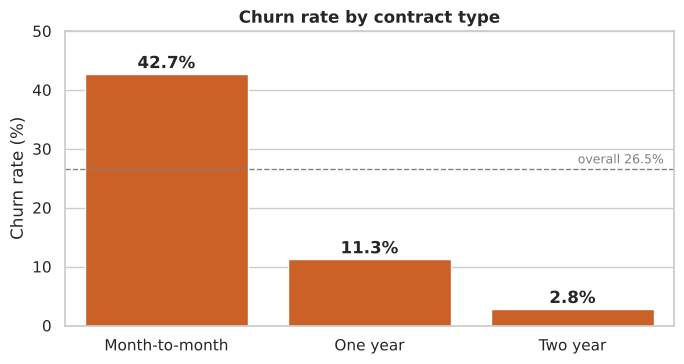

In [14]:
order = ["Month-to-month", "One year", "Two year"]
r = df.groupby("Contract", observed=True)["churn_flag"].mean().reindex(order) * 100
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.barplot(x=r.index, y=r.values, color=COL["Yes"], ax=ax)
for i, v in enumerate(r.values): ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontweight="bold")
ax.axhline(base * 100, ls="--", color="grey", lw=1); ax.text(2.45, base * 100 + 1, f"overall {base:.1%}", ha="right", color="grey", fontsize=9)
ax.set(title="Churn rate by contract type", xlabel="", ylabel="Churn rate (%)", ylim=(0, 50))
plt.tight_layout(); plt.show()

### 6.2 Distribution of tenure (histogram)

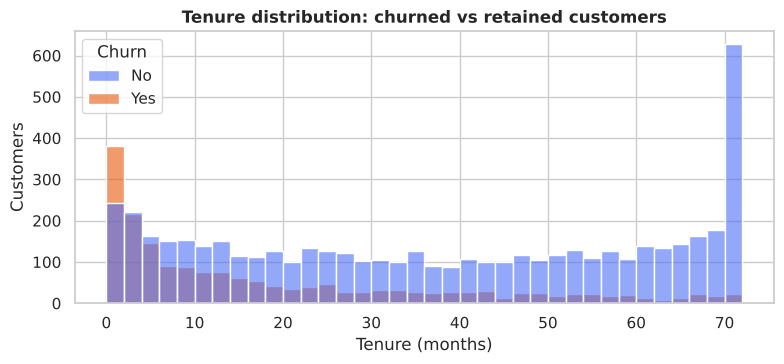

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, palette=COL, multiple="layer", alpha=.6, ax=ax)
ax.set(title="Tenure distribution: churned vs retained customers", xlabel="Tenure (months)", ylabel="Customers")
plt.tight_layout(); plt.show()

### 6.3 Churn rate over tenure (line chart)

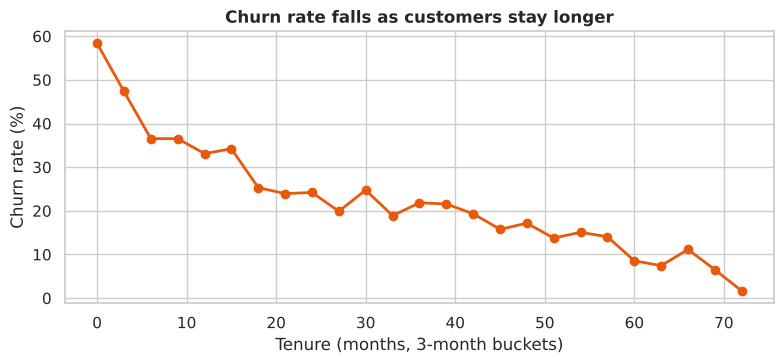

Smallest bucket size: 174 customers


In [16]:
t = df.assign(bucket=(df.tenure // 3) * 3).groupby("bucket")["churn_flag"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(t.index, t["mean"] * 100, marker="o", color=COL["Yes"], lw=2)
ax.set(title="Churn rate falls as customers stay longer", xlabel="Tenure (months, 3-month buckets)", ylabel="Churn rate (%)")
plt.tight_layout(); plt.show()
print("Smallest bucket size:", int(t["size"].min()), "customers")

### 6.4 Box plots: monthly charges and tenure

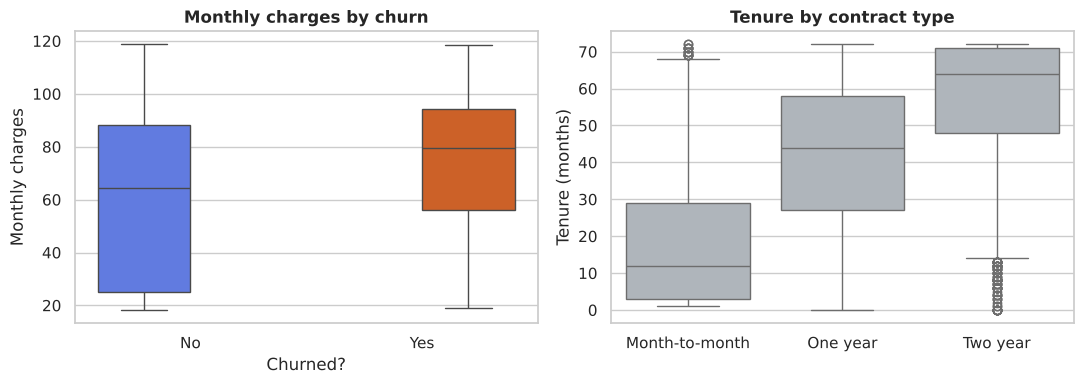

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", palette=COL, legend=False, ax=axes[0]); axes[0].set(title="Monthly charges by churn", xlabel="Churned?", ylabel="Monthly charges")
sns.boxplot(data=df, x="Contract", y="tenure", order=order, color="#ADB5BD", ax=axes[1]); axes[1].set(title="Tenure by contract type", xlabel="", ylabel="Tenure (months)")
plt.tight_layout(); plt.show()

### 6.5 Scatter plot: tenure vs monthly charges

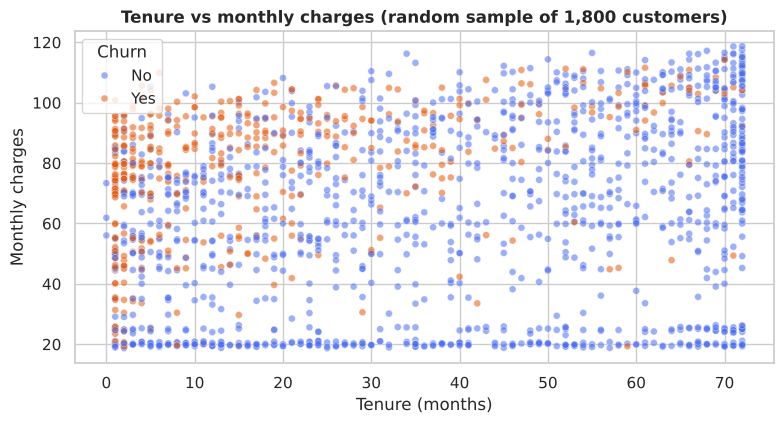

In [18]:
s = df.sample(1800, random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 4.4))
sns.scatterplot(data=s, x="tenure", y="MonthlyCharges", hue="Churn", palette=COL, alpha=.55, s=25, ax=ax)
ax.set(title="Tenure vs monthly charges (random sample of 1,800 customers)", xlabel="Tenure (months)", ylabel="Monthly charges")
plt.tight_layout(); plt.show()

### 6.6 Churn rate by internet service, payment method and add-on services

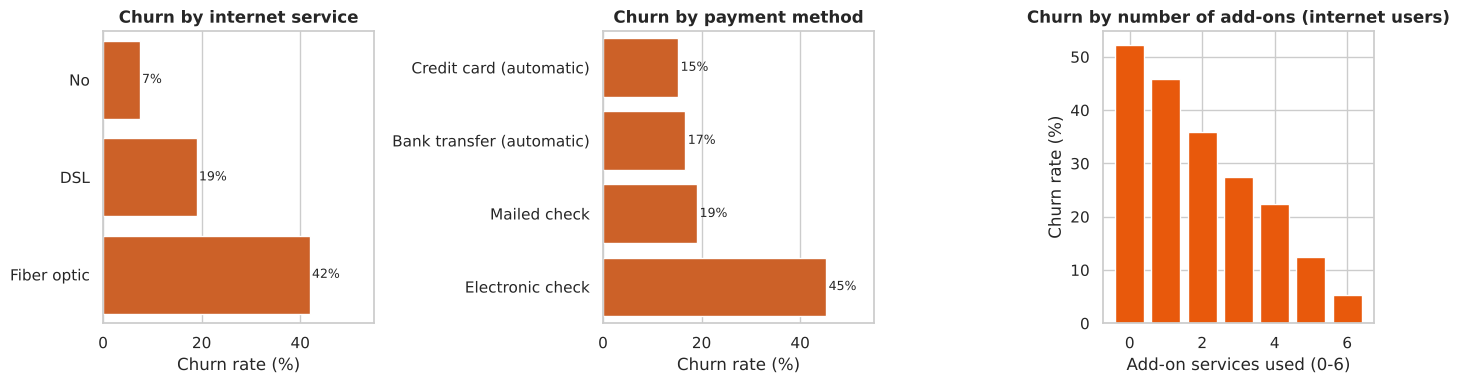

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (c, ttl) in zip(axes[:2], [("InternetService", "Internet service"), ("PaymentMethod", "Payment method")]):
    r = (df.groupby(c, observed=True)["churn_flag"].mean() * 100).sort_values()
    sns.barplot(x=r.values, y=r.index.astype(str), color=COL["Yes"], ax=ax)
    for i, v in enumerate(r.values): ax.text(v + .5, i, f"{v:.0f}%", va="center", fontsize=9)
    ax.set(title=f"Churn by {ttl.lower()}", xlabel="Churn rate (%)", ylabel="", xlim=(0, 55))
r = (df[df.has_internet == "Yes"].groupby("n_addons")["churn_flag"].mean() * 100)
axes[2].bar(r.index, r.values, color=COL["Yes"]); axes[2].set(title="Churn by number of add-ons (internet users)", xlabel="Add-on services used (0-6)", ylabel="Churn rate (%)")
plt.tight_layout(); plt.show()

### 6.7 Heatmaps: contract × internet service and correlations

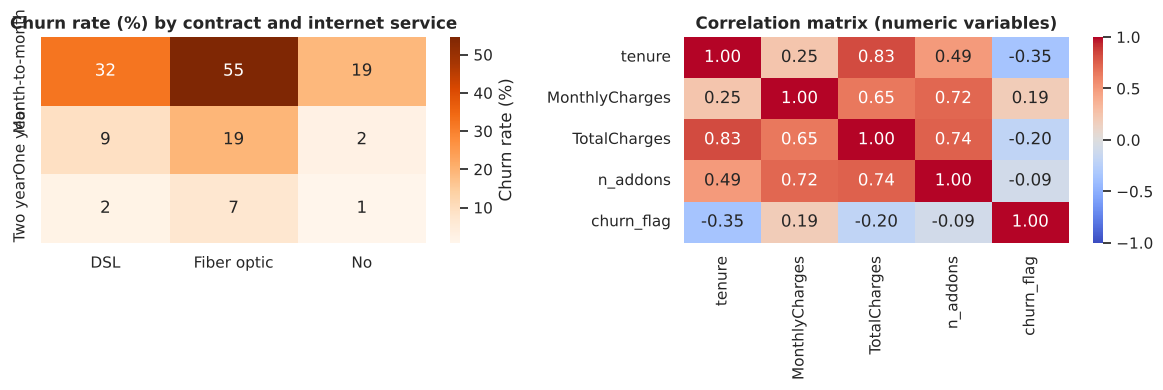

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pv = df.pivot_table(index="Contract", columns="InternetService", values="churn_flag", aggfunc="mean", observed=True).reindex(order) * 100
sns.heatmap(pv, annot=True, fmt=".0f", cmap="Oranges", cbar_kws={"label": "Churn rate (%)"}, ax=axes[0]); axes[0].set(title="Churn rate (%) by contract and internet service", xlabel="", ylabel="")
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1]); axes[1].set_title("Correlation matrix (numeric variables)")
plt.tight_layout(); plt.show()

### 6.8 Customer mix and monthly charge distribution

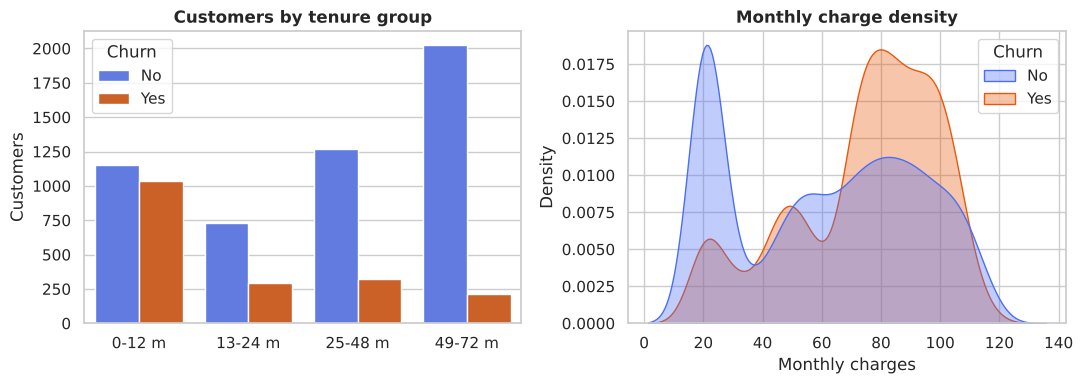

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="tenure_group", hue="Churn", palette=COL, ax=axes[0]); axes[0].set(title="Customers by tenure group", xlabel="", ylabel="Customers")
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", palette=COL, fill=True, common_norm=False, alpha=.35, ax=axes[1]); axes[1].set(title="Monthly charge density", xlabel="Monthly charges")
plt.tight_layout(); plt.show()

**Observations from the charts:** (1) The bar chart shows churn drops sharply from month-to-month to two-year contracts. (2) In the histogram, churned customers pile up at very low tenure while retained customers spread across all tenures with a peak at 70+ months. (3) The line chart shows churn rate falling steadily as tenure grows, with the steepest drop in the first year. (4) The box plots show churned customers pay higher monthly charges (median 79.7 vs 64.4), and two-year contract customers have the longest tenure. (5) In the scatter plot, churned customers (orange) concentrate at low tenure and higher monthly charges. (6) The heatmap shows fiber optic on a month-to-month contract is the riskiest combination (55% churn), while two-year contracts have 7% or less churn for every internet type. (7) The number-of-add-ons chart shows churn falling as more services are used, which fits the idea that customers with more services are more deeply invested; it is an association, not proof.

## 7. Findings, Interpretation and Recommendations

### Key findings
1. **Churn is concentrated, not random.** 26.5% of customers leave, representing 30.5% of monthly revenue.
2. **Contract type and tenure are the strongest signals.** Month-to-month customers in their first year churn at 51.4%; two-year contract customers almost never churn (2.8%).
3. **Fiber optic and electronic-check customers churn about twice as often as others** (41.9% and 45.3%), even though fiber customers are the higher-paying group.
4. **Customers who use security and support services stay longer.** Churn is 14.6% with online security versus 31.3% without it.
5. **One easily identified profile** (month-to-month, fiber optic, electronic check) holds 18.6% of customers but 42.2% of all churners.
6. **Demographics matter less.** Senior citizens (41.7%) and customers without a partner (33.0%) churn more, but gender has no significant effect.

### Interpretation
The pattern suggests that churn is mostly about *commitment and experience*: customers without a long contract are free to leave, and the first year is when they decide. The high churn among fiber customers, who pay the most, may point to price or service-quality issues, but this data cannot tell which. Customers using several add-on services churn less, which may reflect stronger engagement, though it could also simply be that loyal customers buy more.

### Recommendations (to be tested, not guaranteed)
1. **Move month-to-month customers to annual contracts** with a discount or perk, starting with those in their first 12 months.
2. **Build a first-year onboarding and check-in programme**, since 47% of customers churn in that window.
3. **Investigate the fiber optic experience** (pricing, outages, speed versus promise) with customer surveys, since it has the highest churn among internet types.
4. **Encourage automatic payment**, for example with a small credit, because manual and electronic-check payers churn far more.
5. **Offer trials of online security and tech support** to internet customers who have none, and run the test as an A/B experiment to confirm that the add-ons actually reduce churn.
6. **Use the high-risk profile as a simple targeting list** for retention offers, and track results to measure whether the offers pay for themselves.

### Methodology summary
1. Loaded the public IBM Telco Customer Churn dataset (7,043 customers, 21 columns) and documented its context.
2. Explored structure, types, missing values, duplicates, category labels and the target balance.
3. Cleaned on a copy: numeric conversion of `TotalCharges` (with the reason for the fill value), consistent Yes/No encoding, merged redundant labels, categorical dtypes, outlier and consistency checks.
4. Analysed churn by group with rates, Cramér's V / chi-square tests, Mann-Whitney tests, correlations and a segment comparison.
5. Visualised the findings with bar, histogram, line, box, scatter, heatmap, count and density plots.

### Limitations
- One snapshot, no dates: churn is only measured as "left in the last month", so no time-based trends or seasonality can be studied.
- Associations only. For example, customers on fiber optic churn more, but price, service quality, competition or customer type could all explain it; the data cannot separate these.
- Churned customers are the minority (about 27%), so simple accuracy-based conclusions would be misleading if a model were built.
- It is a sample dataset, so the figures should not be read as statistics about a real company.